# NB1 baseline: 30% random label noise and early stopping

**COMP3620 CW3**

## The question

Does early stopping still protect a network from label noise when the mistakes are systematic rather than random?

## What NB1 does

NB1 is the baseline and reproduction notebook. It covers the eight items the group worksheet sets for NB1:

- data and the fixed split;
- design choices and their rationale;
- the clean reference group;
- 30% random label noise;
- learning-rate tuning;
- at least three seeds;
- predictions P1 to P4;
- summary.

## What is being reproduced

We reproduce the memorisation result of Arpit et al., 2017: under random label noise a network fits the clean pattern first and memorises the corrupted labels later, so early stopping keeps most of the test accuracy. The comparison is qualitative rather than a single published number, because the subset, the architecture and the noise implementation are ours.


In [1]:
QUICK = True  # True: load the cached runs and finish in < 5 min; False: run the full experiment


## Pre-registered predictions and metrics, written before looking at results

**P1.** Training accuracy by the given labels first plateaus near 1 − η ≈ 70%, then rises towards ~100%. The plateau is slightly below 70% because the network also makes mistakes on correctly labelled images.

**P2.** Early in training, corrupted training images are more often predicted as their **true** digit than as their **given wrong** label. By the final epoch, the given wrong label is predicted more often than the true digit.

**P3.** Test accuracy first rises and then falls; early stopping preserves most of the peak accuracy.

**P4.** Early stopping on the **noisy validation set** selects a stopping point close to the optimal one. Derivation: let a be true accuracy. Under random noise, noisy validation accuracy = a − aη − aη/9 + η/9, which is monotone in a for η < 0.9.

**Primary metric, fixed now:** test accuracy at the early-stopping epoch, and its gap to the clean reference.

**Secondary metric, fixed now:** test accuracy at the end of training, averaged over the last 10 epochs.

**Practical threshold for P4:** we treat a gap of **less than 1 percentage point** between the selected epoch and the test-optimal epoch as “close”.

**Operational thresholds, fixed now:**

- **P1:** train accuracy at epoch 20 between 0.60 and 0.78, and final train accuracy > 0.95.
- **P2:** at epoch 1, true-digit prediction rate > given-label prediction rate; at the final epoch, given-label rate > true-digit rate.
- **P3:** peak test accuracy − last-10 mean ≥ 0.02, and peak − early-stop test accuracy ≤ 0.02.
- **P4:** mean gap between the early-stopping epoch and the test-optimal epoch < 0.01.


## Shared protocol, from the group worksheet

| Item | Setting |
|---|---|
| Dataset | MNIST, `torchvision.datasets.MNIST` |
| Train | `train=True` images `[0:10000]`, 10,000 |
| Validation | `train=True` images `[50000:55000]`, 5,000 |
| Test | `train=False` images, 10,000; never corrupted |
| Input | pixels scaled to 0 to 1, flattened to 784 |
| Model | MLP 784 → 512 → 512 → 10, ReLU, PyTorch default init |
| Regularisation | none: no dropout, weight decay, BatchNorm, or data augmentation |
| Loss / optimiser | cross-entropy; Adam with default betas/eps, no weight decay |
| Batch size | 128, reshuffled every epoch |
| Epochs | 200, no early stopping during training; evaluate after every epoch |
| Early stopping | after training: epoch with highest **noisy** validation accuracy |
| Noise | η = 0.30, 30% of each class, rounded to the nearest whole image |
| Seeds | 0, 1, 2, plus 3 and 4 if time |
| Learning rates | 1e-4, 3e-4, 1e-3, 3e-3 |


In [2]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

ROOT = Path(".")
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
for p in (DATA_DIR, RESULTS_DIR, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)

NOISE_RATIO = 0.30
NUM_CLASSES = 10
EPOCHS = 200
BATCH_SIZE = 128
HIDDEN = 512
LR_CANDIDATES = [1e-4, 3e-4, 1e-3, 3e-3]
SEEDS = [0, 1, 2]
CONDITIONS_NB1 = ["clean", "random"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("device:", DEVICE)
print("torch:", torch.__version__)
print("results dir:", RESULTS_DIR.resolve())


device: cuda
torch: 2.6.0+cu124
results dir: C:\Users\Larry\Desktop\network GW 1\Notebook\results


In [3]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


## 1. Data and fixed split

The split is fixed once and reused by every seed and every condition. It does not depend on the model or on the noise type.

| Part | Source | Size | Labels |
|---|---|---|---|
| Train | `train=True` images `[0:10000]` | 10,000 | changed according to condition |
| Validation | `train=True` images `[50000:55000]` | 5,000 | changed in the same way; clean copy kept for analysis |
| Test | `train=False` images | 10,000 | never changed |


In [4]:
def load_mnist_split():
    tf = transforms.ToTensor()
    train_full = datasets.MNIST(DATA_DIR, train=True, download=True, transform=tf)
    test_full = datasets.MNIST(DATA_DIR, train=False, download=True, transform=tf)

    train_idx = list(range(0, 10_000))
    val_idx = list(range(50_000, 55_000))

    def to_tensors(dataset):
        xs, ys = [], []
        for x, y in dataset:
            xs.append(x.reshape(-1))
            ys.append(int(y))
        return torch.stack(xs), torch.tensor(ys, dtype=torch.long)

    train_x, train_y = to_tensors(Subset(train_full, train_idx))
    val_x, val_y = to_tensors(Subset(train_full, val_idx))
    test_x, test_y = to_tensors(test_full)
    return train_x, train_y, val_x, val_y, test_x, test_y

train_x, train_y, val_x, val_y, test_x, test_y = load_mnist_split()
data = (train_x, train_y, val_x, val_y, test_x, test_y)

print("train:", tuple(train_x.shape), tuple(train_y.shape), "counts:", np.bincount(train_y.numpy()))
print("val:  ", tuple(val_x.shape), tuple(val_y.shape), "counts:", np.bincount(val_y.numpy()))
print("test: ", tuple(test_x.shape), tuple(test_y.shape), "counts:", np.bincount(test_y.numpy()))
print("pixel range:", float(train_x.min()), float(train_x.max()))


  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:45, 219kB/s]

  1%|          | 65.5k/9.91M [00:00<00:54, 181kB/s]

  2%|▏         | 164k/9.91M [00:00<00:28, 347kB/s] 

  2%|▏         | 229k/9.91M [00:00<00:25, 380kB/s]

  3%|▎         | 328k/9.91M [00:00<00:21, 441kB/s]

... (99 outputs left out)

100%|██████████| 1.65M/1.65M [00:00<00:00, 1.69MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

train: (10000, 784) (10000,) counts: [1001 1127  991 1032  980  863 1014 1070  944  978]
val:   (5000, 784) (5000,) counts: [502 534 497 521 484 457 485 527 515 478]
test:  (10000, 784) (10000,) counts: [ 980 1135 1032 1010  982  892  958 1028  974 1009]
pixel range: 0.0 1.0


## 2. Label noise

- **Random, symmetric:** each selected image is assigned a label drawn uniformly from the other 9 classes; the assigned label is always wrong.
- **Systematic, pair flipping, NB2:** each selected image is assigned the label `c + 1` modulo 10.
- **Clean:** labels unchanged, but the same mask is returned for analysis.

The mask is generated first from `np.random.default_rng`, seeded with the pair `seed` and `split_id`, so it is identical for clean/random/systematic. Training uses `split_id=0`; validation uses `split_id=1`; the test set is never touched.

We use integer labels, so no one-hot regeneration is needed. If the lab machine has no internet, pre-download MNIST into `data/` before running the notebook.

Because the fixed 10k/5k splits are not exactly balanced across classes, the number selected per class is rounded to the nearest image. The realised ratio therefore differs from 30% by at most 0.5 image per class; the check below prints the actual per-class ratios.


In [5]:
def make_mask(labels, ratio, rng):
    labels = np.asarray(labels)
    mask = np.zeros(len(labels), dtype=bool)
    for c in range(NUM_CLASSES):
        idx = np.flatnonzero(labels == c)
        n = int(round(len(idx) * ratio))
        if n > 0:
            mask[rng.choice(idx, size=n, replace=False)] = True
    return mask


def corrupt_labels(labels, noise_type, ratio, seed, split_id):
    labels = np.asarray(labels)
    rng = np.random.default_rng([seed, split_id])
    # Generate the mask first: it is identical for clean/random/systematic.
    mask = make_mask(labels, ratio, rng)
    corrupted = labels.copy()

    if noise_type == "random" and mask.any():
        true = labels[mask]
        wrong = rng.integers(0, NUM_CLASSES - 1, size=len(true))
        wrong = np.where(wrong >= true, wrong + 1, wrong)  # uniformly skip the true class
        corrupted[mask] = wrong
    elif noise_type == "systematic" and mask.any():
        corrupted[mask] = (labels[mask] + 1) % NUM_CLASSES
    elif noise_type == "clean":
        pass
    else:
        raise ValueError(f"unknown noise_type: {noise_type}")

    return corrupted, mask


def transition_table(true_labels, given_labels, mask=None, only_masked=False):
    """10x10 table of true digit against given label, row-normalised.

    By default every image of a class is counted, which is the orientation the
    shared protocol specifies: under 30% random noise the diagonal is 0.70 and
    each of the other nine cells is about 0.033; under paired flipping the
    diagonal is 0.70 and the "next digit" cell is 0.30.

    only_masked=True restricts the table to the corrupted images, giving diagonal
    0 and 1/9 per off-diagonal cell under random noise. That answers a different
    question, namely what a corrupted image was corrupted to, and is kept as a
    secondary view.
    """
    true_labels = np.asarray(true_labels)
    given_labels = np.asarray(given_labels)
    if mask is not None and only_masked:
        true_labels = true_labels[mask]
        given_labels = given_labels[mask]
    table = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
    for t, g in zip(true_labels, given_labels):
        table[t, g] += 1
    row_sums = table.sum(axis=1, keepdims=True)
    return table, table / np.maximum(row_sums, 1)


def check_transition(labels, corrupted, mask, noise_type, n_sigma=4.5):
    """Check a noise table against the shape the shared protocol predicts.

    Tolerances are derived from the actual class counts instead of being hard-coded.
    The diagonal is exact by construction, because the mask corrupts round(r * n_c)
    images of class c, so the diagonal is 1 - round(r * n_c) / n_c, and it gets a
    tight tolerance. An off-diagonal cell holds about r * n_c / 9 corrupted images
    and is therefore a binomial count, with normalised standard deviation
    sqrt((r/9)/n_c); the tolerance is n_sigma of that. A fixed tolerance would
    either fail at random on the 5,000-image validation split or be too loose to
    detect a real error.
    """
    labels = np.asarray(labels)
    _, row_norm = transition_table(labels, corrupted)
    diag = np.diag(row_norm)

    counts = np.bincount(labels, minlength=NUM_CLASSES)
    n_min = max(int(counts[counts > 0].min()), 1)
    diag_tol = 0.5 / n_min + 0.002
    cell_tol = n_sigma * float(np.sqrt((NOISE_RATIO / (NUM_CLASSES - 1)) / n_min))

    if noise_type == "systematic":
        next_digit = np.array([row_norm[c, (c + 1) % NUM_CLASSES] for c in range(NUM_CLASSES)])
        others = row_norm.copy()
        for c in range(NUM_CLASSES):
            others[c, c] = 0.0
            others[c, (c + 1) % NUM_CLASSES] = 0.0
        ok = (
            np.all(np.abs(diag - (1 - NOISE_RATIO)) <= diag_tol)
            and np.all(np.abs(next_digit - NOISE_RATIO) <= cell_tol)
            and np.all(others <= cell_tol)
        )
        detail = (f"diagonal {diag.min():.3f} to {diag.max():.3f}, want {1 - NOISE_RATIO:.2f} +/-{diag_tol:.3f}, "
                  f"next digit {next_digit.min():.3f} to {next_digit.max():.3f}, want {NOISE_RATIO:.2f} +/-{cell_tol:.3f}, "
                  f"all other cells <= {others.max():.3f}")
        return ok, row_norm, detail

    off = row_norm[~np.eye(NUM_CLASSES, dtype=bool)]
    target = NOISE_RATIO / (NUM_CLASSES - 1)
    ok = (
        np.all(np.abs(diag - (1 - NOISE_RATIO)) <= diag_tol)
        and np.all(np.abs(off - target) <= cell_tol)
    )
    detail = (f"diagonal {diag.min():.3f} to {diag.max():.3f}, want {1 - NOISE_RATIO:.2f} +/-{diag_tol:.3f}, "
              f"off-diagonal {off.min():.3f} to {off.max():.3f}, want {target:.3f} +/-{cell_tol:.3f}")
    return ok, row_norm, detail


def check_noise(labels, seed, split_id, name):
    labels = np.asarray(labels)
    print(f"\n=== {name} | seed {seed} ===")
    masks = {}
    for noise_type in ["clean", "random", "systematic"]:
        corrupted, mask = corrupt_labels(labels, noise_type, NOISE_RATIO, seed, split_id)
        masks[noise_type] = mask
        ratios = [
            ((labels == c) & mask).sum() / max((labels == c).sum(), 1)
            for c in range(NUM_CLASSES)
        ]
        print(f"{noise_type:10s} per-class ratio: min={min(ratios):.4f} max={max(ratios):.4f}")
        if noise_type in ("random", "systematic"):
            ok, row_norm, detail = check_transition(labels, corrupted, mask, noise_type)
            print("  full transition table, rows = true digit, cols = given label:")
            print(np.round(row_norm, 3))
            print(f"  check: {detail}  -> {'PASS' if ok else 'FAIL'}")
            _, masked_norm = transition_table(labels, corrupted, mask, only_masked=True)
            print("  restricted to corrupted images only, secondary view:")
            print(np.round(masked_norm, 3))

    same = (
        np.array_equal(masks["clean"], masks["random"])
        and np.array_equal(masks["clean"], masks["systematic"])
    )
    print("same mask across noise types:", same)


check_noise(train_y.numpy(), seed=0, split_id=0, name="train")
check_noise(val_y.numpy(), seed=0, split_id=1, name="val")

print("\nCompact check across all seeds:")
for s in SEEDS:
    for split_id, labels, name in [(0, train_y.numpy(), "train"), (1, val_y.numpy(), "val")]:
        masks = {}
        ratios_ok = True
        for nt in ["clean", "random", "systematic"]:
            _, m = corrupt_labels(labels, nt, NOISE_RATIO, s, split_id)
            masks[nt] = m
            ratios = [((labels == c) & m).sum() / max((labels == c).sum(), 1) for c in range(NUM_CLASSES)]
            # Counts are rounded to the nearest image, so the realised ratio can differ
            # from 0.30 by at most 0.5 image per class.
            ratios_ok = ratios_ok and all(
                abs(r - NOISE_RATIO) <= 0.5 / max((labels == c).sum(), 1) + 1e-12
                for c, r in enumerate(ratios)
            )
        same = (
            np.array_equal(masks["clean"], masks["random"])
            and np.array_equal(masks["clean"], masks["systematic"])
        )
        print(f"seed {s} {name}: ratios_ok={ratios_ok}, same_mask={same}")



=== train | seed 0 ===
clean      per-class ratio: min=0.2996 max=0.3004
random     per-class ratio: min=0.2996 max=0.3004
  full transition table, rows = true digit, cols = given label:
[[0.7   0.037 0.042 0.024 0.03  0.023 0.036 0.032 0.039 0.037]
 [0.035 0.7   0.03  0.043 0.036 0.027 0.032 0.028 0.035 0.034]
 [0.031 0.03  0.7   0.037 0.039 0.035 0.025 0.034 0.038 0.028]
 [0.044 0.021 0.037 0.7   0.036 0.021 0.04  0.041 0.031 0.03 ]
 [0.037 0.037 0.037 0.03  0.7   0.037 0.027 0.033 0.032 0.033]
 [0.03  0.028 0.034 0.031 0.035 0.7   0.032 0.049 0.028 0.034]
 [0.039 0.035 0.033 0.036 0.033 0.036 0.7   0.04  0.029 0.019]
 [0.034 0.039 0.033 0.033 0.029 0.036 0.034 0.7   0.038 0.024]
 [0.036 0.033 0.03  0.034 0.03  0.035 0.032 0.034 0.7   0.037]
 [0.027 0.04  0.036 0.024 0.029 0.039 0.03  0.037 0.04  0.7  ]]
  check: diagonal 0.700 to 0.700, want 0.70 +/-0.003, off-diagonal 0.019 to 0.049, want 0.033 +/-0.028  -> PASS
  restricted to corrupted images only, secondary view:
[[0.    0.123 

## 3. Model and training protocol

Design choices and rationale:

- **10,000 training images.** Small enough that a high-capacity MLP can memorise the noisy labels within 200 epochs, and large enough that the clean pattern is still learnable.
- **784 → 512 → 512 → 10 MLP.** Enough capacity to fit the training set; PyTorch default initialisation; ReLU.
- **No regularisation.** No dropout, weight decay, BatchNorm, or data augmentation. These would slow memorisation and make it unclear whether a difference is due to the noise type or to regularisation. This is also a scope limitation.
- **Adam, default betas/eps, no weight decay; batch size 128; 200 epochs.** Fixed for every seed and condition. No early stopping during training, so the full curve is available; the stopping epoch is chosen afterwards from the noisy validation curve.
- **Cross-entropy**, integer labels. The test set is evaluated after every epoch but is never used for tuning or stopping.

The function `train_one_run` below is the shared training function. **NB2 must copy this whole training block** `set_seed`, `corrupt_labels`, `MLP`, `predict`, `compute_metrics`, `train_one_run` verbatim, so that the only difference is the noise type.

### What the seed controls

Per the shared protocol the seed fixes three channels and nothing else:

- **which images are corrupted and what they are corrupted to**, from `np.random.default_rng` with the pair `seed` and `split_id`, where `split_id=0` is train and `split_id=1` is validation. The mask depends on the seed only, so all three noise types corrupt the same images;
- **weight initialisation**, from `torch.manual_seed` inside `set_seed`;
- **batch order**, from a separate `torch.Generator` seeded with the same seed.

The split, the test set and the dropout masks are not affected: the split is fixed in code, the test set is never touched, and this model has no dropout. Because the mask is a function of the seed, the three seeds are three independent noise realisations, so the spread in section 5 covers both initialisation noise and noise-realisation noise.


In [6]:
class MLP(nn.Module):
    def __init__(self, hidden=HIDDEN, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, num_classes),
        )

    def forward(self, x):
        return self.net(x)


@torch.inference_mode()
def predict(model, loader):
    model.eval()
    preds = []
    for x, _ in loader:
        preds.append(model(x.to(DEVICE)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()


def compute_metrics(model, train_loader, val_loader, test_loader,
                    train_y_clean, train_y_given, train_mask,
                    val_y_clean, val_y_given, test_y, condition):
    train_pred = predict(model, train_loader)
    val_pred = predict(model, val_loader)
    test_pred = predict(model, test_loader)

    train_acc_given = float((train_pred == train_y_given).mean())

    if train_mask.any():
        selected_pred_true = float((train_pred[train_mask] == train_y_clean[train_mask]).mean())
        nonselected_pred_true = (
            float((train_pred[~train_mask] == train_y_clean[~train_mask]).mean())
            if (~train_mask).any() else None
        )
        selected_pred_given = (
            None if condition == "clean"
            else float((train_pred[train_mask] == train_y_given[train_mask]).mean())
        )
    else:
        selected_pred_true = None
        nonselected_pred_true = None
        selected_pred_given = None

    val_acc_noisy = float((val_pred == val_y_given).mean())
    val_acc_clean = float((val_pred == val_y_clean).mean())
    test_acc = float((test_pred == test_y).mean())

    errors = test_pred != test_y
    if errors.any():
        next_digit = (test_y + 1) % NUM_CLASSES
        test_err_next = float((test_pred[errors] == next_digit[errors]).mean())
    else:
        test_err_next = None

    return {
        "epoch": None,
        "train_acc_given": train_acc_given,
        "selected_pred_true": selected_pred_true,
        "selected_pred_given": selected_pred_given,
        "nonselected_pred_true": nonselected_pred_true,
        "val_acc_noisy": val_acc_noisy,
        "val_acc_clean": val_acc_clean,
        "test_acc": test_acc,
        "test_err_next": test_err_next,
    }


def train_one_run(condition, lr, seed, data, epochs=EPOCHS, batch_size=BATCH_SIZE,
                  demo=False, verbose=True):
    train_x, train_y_clean_t, val_x, val_y_clean_t, test_x, test_y_t = data
    set_seed(seed)

    train_y_clean = train_y_clean_t.numpy()
    val_y_clean = val_y_clean_t.numpy()
    test_y = test_y_t.numpy()

    train_y_given, train_mask = corrupt_labels(
        train_y_clean, condition, NOISE_RATIO, seed, split_id=0
    )
    val_y_given, _ = corrupt_labels(
        val_y_clean, condition, NOISE_RATIO, seed, split_id=1
    )

    if demo:
        n_train = min(2000, len(train_x))
        n_val = min(1000, len(val_x))
        n_test = min(1000, len(test_x))
        train_x = train_x[:n_train]
        train_y_clean = train_y_clean[:n_train]
        train_y_given = train_y_given[:n_train]
        train_mask = train_mask[:n_train]
        val_x = val_x[:n_val]
        val_y_clean = val_y_clean[:n_val]
        val_y_given = val_y_given[:n_val]
        test_x = test_x[:n_test]
        test_y = test_y[:n_test]

    train_ds = TensorDataset(train_x, torch.tensor(train_y_given, dtype=torch.long))
    val_ds = TensorDataset(val_x, torch.tensor(val_y_given, dtype=torch.long))
    test_ds = TensorDataset(test_x, torch.tensor(test_y, dtype=torch.long))

    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g)
    train_eval_loader = DataLoader(train_ds, batch_size=512, shuffle=False)
    val_loader = DataLoader(val_ds, batch_size=512, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=512, shuffle=False)

    model = MLP().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # default betas/eps, no weight decay
    loss_fn = nn.CrossEntropyLoss()

    history = []
    t0 = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()

        metrics = compute_metrics(
            model, train_eval_loader, val_loader, test_loader,
            train_y_clean, train_y_given, train_mask,
            val_y_clean, val_y_given, test_y, condition,
        )
        metrics["epoch"] = epoch
        history.append(metrics)

        if verbose and (epoch % 20 == 0 or epoch == epochs):
            print(
                f"  epoch {epoch:3d}/{epochs} | train {metrics['train_acc_given']:.3f} "
                f"| val noisy {metrics['val_acc_noisy']:.3f} | test {metrics['test_acc']:.3f}"
            )

    val_noisy = np.array([h["val_acc_noisy"] for h in history])
    test_acc = np.array([h["test_acc"] for h in history])
    best_epoch = int(np.argmax(val_noisy)) + 1
    optimal_test_epoch = int(np.argmax(test_acc)) + 1

    metrics_dict = {key: [h[key] for h in history] for key in history[0]}

    return {
        "config": {
            "condition": condition,
            "lr": float(lr),
            "seed": int(seed),
            "epochs": int(epochs),
            "batch_size": int(batch_size),
            "noise_ratio": float(NOISE_RATIO),
            "noise_type": condition,
            "num_classes": int(NUM_CLASSES),
            "hidden": int(HIDDEN),
            "model": "MLP 784-512-512-10, ReLU, PyTorch default init",
            "regularisation": "none: no dropout, weight decay, BatchNorm, or augmentation",
            "optimizer": "Adam, default betas/eps, no weight decay",
            "dataset": "MNIST",
            "split": "train [0:10000], val [50000:55000], test all 10000",
            "seeds": [int(x) for x in SEEDS],
            "lr_candidates": [float(x) for x in LR_CANDIDATES],
            "demo": bool(demo),
            "torch_version": torch.__version__,
            "device": str(DEVICE),
        },
        "metrics": metrics_dict,
        "early_stop": {
            "epoch": best_epoch,
            "val_acc_noisy": float(val_noisy[best_epoch - 1]),
            "test_acc_at_stop": float(test_acc[best_epoch - 1]),
            "test_acc_last10_mean": float(test_acc[-10:].mean()),
            "max_test_acc": float(test_acc.max()),
            "optimal_test_epoch": optimal_test_epoch,
            "gap_to_optimal_test_acc": float(test_acc.max() - test_acc[best_epoch - 1]),
        },
        "wall_time_s": float(time.perf_counter() - t0),
    }


## 4. Learning-rate tuning

For each condition, the four candidate learning rates are run with seeds 0 to 2. The selected rate is the one with the highest **mean early-stopping noisy validation accuracy** across the three seeds. The three runs at the selected rate are the formal results; they are not rerun.

NB1 tunes `clean` and `random`, 2 × 4 × 3 = 24 runs. NB2 tunes `systematic` with the same four candidates and seeds, 12 more runs, giving 36 runs across the project.

The `train_final_mean` column checks the `1e-4` lower bound: if `1e-4` has not reached ~100% training accuracy by epoch 200, it has not memorised the noisy labels; if it has, it is still the slowest candidate in the grid.

One extra run at `3e-5`, `random`, seed 0 confirms the bound directly. It is not part of the 24 formal runs or the 36-run grid; it only tests whether an even smaller learning rate fails to memorise within 200 epochs.


In [7]:
def result_path(condition, lr, seed):
    return RESULTS_DIR / f"{condition}_lr{lr:g}_seed{seed}.json"


def save_result(result):
    cfg = result["config"]
    path = result_path(cfg["condition"], cfg["lr"], cfg["seed"])
    path.write_text(json.dumps(result, indent=2))
    return path


def load_result(condition, lr, seed):
    return json.loads(result_path(condition, lr, seed).read_text())


CACHE_PATHS = [
    result_path(condition, lr, seed)
    for condition in CONDITIONS_NB1
    for lr in LR_CANDIDATES
    for seed in SEEDS
]
CACHE_COMPLETE = all(p.exists() for p in CACHE_PATHS)
print(f"cache: {sum(p.exists() for p in CACHE_PATHS)}/{len(CACHE_PATHS)} files present")

DEMO_ONLY = QUICK and not CACHE_COMPLETE
if DEMO_ONLY:
    print("QUICK=True but the cache is incomplete: running a short demo only.")
    print("Set QUICK=False in a dl2026 kernel to generate the full cache.")

all_results = []

if QUICK and CACHE_COMPLETE:
    for condition in CONDITIONS_NB1:
        for lr in LR_CANDIDATES:
            for seed in SEEDS:
                all_results.append(load_result(condition, lr, seed))
    print("loaded", len(all_results), "cached runs")
    print("QUICK smoke test: one short run, 2 epochs and 2k images")
    _demo = train_one_run("random", 1e-3, 0, data, epochs=2, demo=True, verbose=False)
    print("smoke-test test acc:", round(_demo["early_stop"]["test_acc_at_stop"], 3))

elif QUICK:
    all_results.append(train_one_run("clean", 1e-3, 0, data, epochs=2, demo=True))
    all_results.append(train_one_run("random", 1e-3, 0, data, epochs=2, demo=True))

else:
    for condition in CONDITIONS_NB1:
        for lr in LR_CANDIDATES:
            for seed in SEEDS:
                print(f"\n=== {condition} | lr={lr:g} | seed={seed} ===")
                result = train_one_run(condition, lr, seed, data)
                save_result(result)
                all_results.append(result)
    print("\nfull NB1 run complete")

LOWER_BOUND_LR = 3e-5
LOWER_BOUND_PATH = RESULTS_DIR / f"nb1_lower_bound_random_lr{LOWER_BOUND_LR:g}_seed0.json"

if not QUICK:
    print(f"\n=== lower-bound check | random | lr={LOWER_BOUND_LR:g} | seed=0 ===")
    _lb = train_one_run("random", LOWER_BOUND_LR, 0, data)
    LOWER_BOUND_PATH.write_text(json.dumps(_lb, indent=2))
elif LOWER_BOUND_PATH.exists():
    _lb = json.loads(LOWER_BOUND_PATH.read_text())
else:
    _lb = None

if _lb is not None:
    print(
        "lower-bound check: final train acc =",
        round(_lb["metrics"]["train_acc_given"][-1], 3),
        "| early-stop test acc =",
        round(_lb["early_stop"]["test_acc_at_stop"], 3),
    )
else:
    print("lower-bound check not cached; run QUICK=False to generate it.")


cache: 24/24 files present
loaded 24 cached runs
QUICK smoke test: one short run, 2 epochs and 2k images


smoke-test test acc: 0.789
lower-bound check: final train acc = 0.762 | early-stop test acc = 0.924


In [8]:
rows = []
for r in all_results:
    cfg = r["config"]
    es = r["early_stop"]
    rows.append({
        "condition": cfg["condition"],
        "lr": cfg["lr"],
        "seed": cfg["seed"],
        "epochs": cfg["epochs"],
        "demo": cfg["demo"],
        "early_stop_epoch": es["epoch"],
        "early_stop_val_noisy": es["val_acc_noisy"],
        "test_acc_at_stop": es["test_acc_at_stop"],
        "test_acc_last10": es["test_acc_last10_mean"],
        "max_test_acc": es["max_test_acc"],
        "optimal_test_epoch": es["optimal_test_epoch"],
        "gap_to_optimal": es["gap_to_optimal_test_acc"],
        "train_acc_final": r["metrics"]["train_acc_given"][-1],
    })

df = pd.DataFrame(rows)

tune = (
    df.groupby(["condition", "lr"])
      .agg(
          n=("seed", "count"),
          val_noisy_mean=("early_stop_val_noisy", "mean"),
          val_noisy_std=("early_stop_val_noisy", "std"),
          test_stop_mean=("test_acc_at_stop", "mean"),
          test_stop_std=("test_acc_at_stop", "std"),
          test_last10_mean=("test_acc_last10", "mean"),
          train_final_mean=("train_acc_final", "mean"),
      )
      .reset_index()
)

selected_rows = (
    tune.sort_values(["condition", "val_noisy_mean"], ascending=[True, False])
        .groupby("condition", as_index=False)
        .head(1)
)
selected_lr = dict(zip(selected_rows["condition"], selected_rows["lr"]))

print("selected learning rates:", selected_lr)
print("\nLearning-rate tuning table, mean over seeds:")
print(tune.to_string(index=False))

print("\nFinal train accuracy, check of the 1e-4 lower bound:")
print(tune.pivot(index="lr", columns="condition", values="train_final_mean"))


selected learning rates: {'clean': 0.003, 'random': 0.001}

Learning-rate tuning table, mean over seeds:
condition     lr  n  val_noisy_mean  val_noisy_std  test_stop_mean  test_stop_std  test_last10_mean  train_final_mean
    clean 0.0001  3        0.952667       0.000503        0.953633       0.001823          0.954530          1.000000
    clean 0.0003  3        0.954867       0.000702        0.956467       0.000115          0.957303          1.000000
    clean 0.0010  3        0.960933       0.000306        0.960567       0.001159          0.961510          1.000000
    clean 0.0030  3        0.965667       0.000306        0.964867       0.001750          0.967097          1.000000
   random 0.0001  3        0.648133       0.001026        0.929467       0.003931          0.741313          0.997033
   random 0.0003  3        0.649533       0.000987        0.929567       0.002281          0.754580          1.000000
   random 0.0010  3        0.652267       0.001943        0.934100   

## 5. Formal results at the selected learning rate

**Primary:** test accuracy at the noisy-validation early-stopping epoch, and the gap to the clean reference.

**Secondary:** test accuracy at the end of training, mean of the last 10 epochs.

**Spread.** For each condition we report the mean and the standard deviation over the three seeds, and the stopping epoch as a range rather than a mean, because it is a discrete argmax. The printed effect over standard error compares the reference minus baseline gap with that spread, so the gap is read against seed noise rather than on its own.


In [9]:
formal = df[df.apply(lambda r: np.isclose(r["lr"], selected_lr[r["condition"]]), axis=1)].copy()
formal = formal.sort_values(["condition", "seed"])

formal_view = formal[[
    "condition", "lr", "seed", "early_stop_epoch", "early_stop_val_noisy",
    "test_acc_at_stop", "test_acc_last10", "max_test_acc",
    "optimal_test_epoch", "gap_to_optimal", "train_acc_final"
]].copy()
formal_view


,condition,lr,seed,early_stop_epoch,early_stop_val_noisy,test_acc_at_stop,test_acc_last10,max_test_acc,optimal_test_epoch,gap_to_optimal,train_acc_final
9,clean,0.003,0,17,0.9660,0.9631,0.96582,0.9661,200,0.0030,1.0
10,clean,0.003,1,127,0.9656,0.9666,0.96773,0.9679,187,0.0013,1.0
11,clean,0.003,2,72,0.9654,0.9649,0.96774,0.9679,185,0.0030,1.0
18,random,0.001,0,5,0.6506,0.9285,0.77156,0.9285,5,0.0000,1.0
19,random,0.001,1,5,0.6518,0.9347,0.76743,0.9347,5,0.0000,1.0
20,random,0.001,2,5,0.6544,0.9391,0.78618,0.9391,5,0.0000,1.0


In [10]:
formal_summary = (
    formal.groupby("condition")
          .agg(
              n=("seed", "count"),
              val_noisy_mean=("early_stop_val_noisy", "mean"),
              val_noisy_std=("early_stop_val_noisy", "std"),
              test_stop_mean=("test_acc_at_stop", "mean"),
              test_stop_std=("test_acc_at_stop", "std"),
              test_last10_mean=("test_acc_last10", "mean"),
              test_last10_std=("test_acc_last10", "std"),
              max_test_mean=("max_test_acc", "mean"),
          )
          .reset_index()
)

if {"clean", "random"}.issubset(set(formal_summary["condition"])):
    clean_row = formal_summary.set_index("condition").loc["clean"]
    random_row = formal_summary.set_index("condition").loc["random"]
    print(f"reference minus baseline at early stop: "
          f"{clean_row['test_stop_mean'] - random_row['test_stop_mean']:.4f}")
    print(f"reference minus baseline at end, last 10 epochs: "
          f"{clean_row['test_last10_mean'] - random_row['test_last10_mean']:.4f}")


def spread_report(df_formal):
    rows = []
    for cond in CONDITIONS_NB1:
        sub = df_formal[df_formal["condition"] == cond]
        if not len(sub):
            continue
        n = int(len(sub))
        rows.append({
            "condition": cond,
            "n_seeds": n,
            "test_at_stop_mean": float(sub["test_acc_at_stop"].mean()),
            "test_at_stop_sd": float(sub["test_acc_at_stop"].std(ddof=1)) if n > 1 else float("nan"),
            "test_last10_mean": float(sub["test_acc_last10"].mean()),
            "test_last10_sd": float(sub["test_acc_last10"].std(ddof=1)) if n > 1 else float("nan"),
            "stop_epoch_range": f"{int(sub['early_stop_epoch'].min())}-{int(sub['early_stop_epoch'].max())}",
            "gap_to_optimal_mean": float(sub["gap_to_optimal"].mean()),
            "gap_to_optimal_max": float(sub["gap_to_optimal"].max()),
        })
    return pd.DataFrame(rows)


spread = spread_report(formal)
print("\nSeed-to-seed spread of the formal results, mean ± sd over seeds:")
print(spread.to_string(index=False))

if {"clean", "random"}.issubset(set(spread["condition"])):
    c = spread.set_index("condition").loc["clean"]
    r = spread.set_index("condition").loc["random"]

    if int(c["n_seeds"]) < 2 or int(r["n_seeds"]) < 2:
        print("\nSpread cannot be analysed: fewer than 2 seeds per condition. "
              "This is the demo path, QUICK=True with an incomplete results/ cache. "
              "Re-run with QUICK=False in the dl2026 kernel.")
    else:
        for metric in ["test_at_stop", "test_last10"]:
            effect = float(c[f"{metric}_mean"] - r[f"{metric}_mean"])
            se = float(np.sqrt(
                c[f"{metric}_sd"] ** 2 / c["n_seeds"] + r[f"{metric}_sd"] ** 2 / r["n_seeds"]
            ))
            ratio = effect / se if se > 0 else float("inf")
            if ratio >= 2:
                verdict = "clears seed noise, effect >= 2 SE"
            elif ratio >= 1:
                verdict = "comparable to seed noise, 1 SE <= effect < 2 SE, report with caution"
            else:
                verdict = "inside seed noise, effect < 1 SE, not interpretable on its own"
            print(f"\n{metric}: reference minus baseline = {effect:+.4f}; "
                  f"pooled SE = {se:.4f}; effect/SE = {ratio:.2f}  -> {verdict}")

        print(f"\nStop-epoch stability across seeds: clean {c['stop_epoch_range']}, "
              f"random {r['stop_epoch_range']}")
        print("Reading: the stopping epoch is the least stable quantity recorded here. "
              "Wide and differing ranges mean NB2 must not treat a shift in stop epoch as a "
              "change in the phenomenon, only as a change in where the noisy validation curve peaks. "
              "The judgement that matters for NB2 is the effect/SE ratio above: if the clean-random "
              "gap already sits inside seed noise at 30% random noise, a smaller gap under systematic "
              "noise could not be distinguished without more seeds.")

formal_summary


reference minus baseline at early stop: 0.0308
reference minus baseline at end, last 10 epochs: 0.1920

Seed-to-seed spread of the formal results, mean ± sd over seeds:
condition  n_seeds  test_at_stop_mean  test_at_stop_sd  test_last10_mean  test_last10_sd stop_epoch_range  gap_to_optimal_mean  gap_to_optimal_max
    clean        3           0.964867         0.001750          0.967097        0.001106           17-127             0.002433               0.003
   random        3           0.934100         0.005325          0.775057        0.009852              5-5             0.000000               0.000

test_at_stop: reference minus baseline = +0.0308; pooled SE = 0.0032; effect/SE = 9.51  -> clears seed noise, effect >= 2 SE

test_last10: reference minus baseline = +0.1920; pooled SE = 0.0057; effect/SE = 33.55  -> clears seed noise, effect >= 2 SE

Stop-epoch stability across seeds: clean 17-127, random 5-5
Reading: the stopping epoch is the least stable quantity recorded here. Wide 

,condition,n,val_noisy_mean,val_noisy_std,test_stop_mean,test_stop_std,test_last10_mean,test_last10_std,max_test_mean
0,clean,3,0.965667,0.000306,0.964867,0.001750,0.967097,0.001106,0.9673
1,random,3,0.652267,0.001943,0.934100,0.005325,0.775057,0.009852,0.9341


## 6. Testing predictions P1 to P4

The cells below plot and summarise the evidence for each prediction.


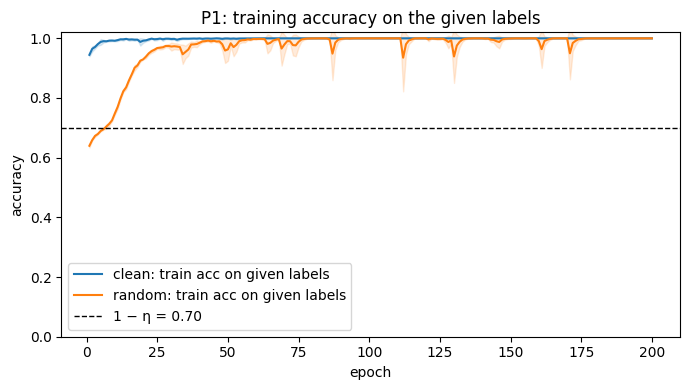

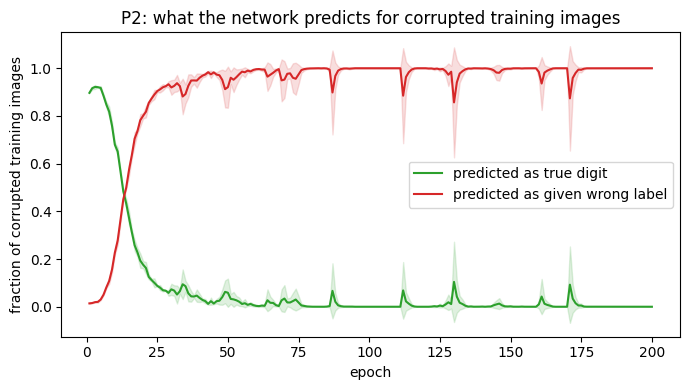

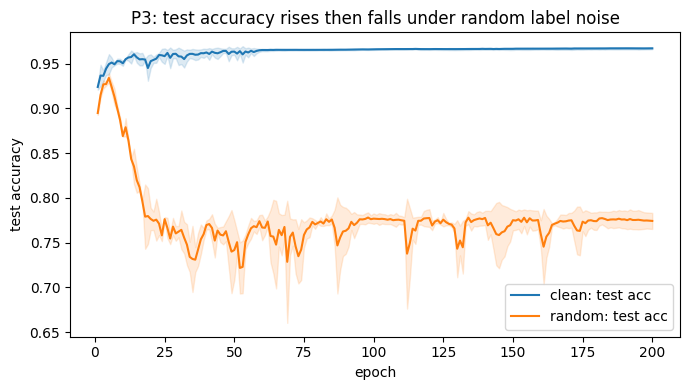

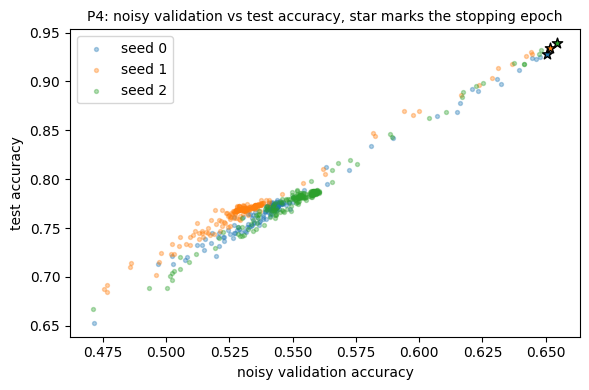

In [11]:
def histories_for(condition, lr):
    return [
        r["metrics"] for r in all_results
        if r["config"]["condition"] == condition and np.isclose(r["config"]["lr"], lr)
    ]


def curve_stats(histories, key):
    arr = np.array(
        [[np.nan if v is None else v for v in hist[key]] for hist in histories],
        dtype=float,
    )
    mean = np.nanmean(arr, axis=0)
    std = np.nanstd(arr, axis=0, ddof=1) if arr.shape[0] > 1 else np.zeros_like(mean)
    return mean, np.nan_to_num(std, nan=0.0)


fig, ax = plt.subplots(figsize=(7, 4))
for condition, color in [("clean", "C0"), ("random", "C1")]:
    hists = histories_for(condition, selected_lr[condition])
    if not hists:
        continue
    mean, std = curve_stats(hists, "train_acc_given")
    x = np.arange(1, len(mean) + 1)
    ax.plot(x, mean, color=color, label=f"{condition}: train acc on given labels")
    ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.15)
ax.axhline(1 - NOISE_RATIO, color="k", ls="--", lw=1, label="1 − η = 0.70")
ax.set_xlabel("epoch")
ax.set_ylabel("accuracy")
ax.set_ylim(0, 1.02)
ax.set_title("P1: training accuracy on the given labels")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "nb1_p1_train_acc_given.png", dpi=150)
plt.show()

hists = histories_for("random", selected_lr["random"])
fig, ax = plt.subplots(figsize=(7, 4))
if hists:
    mean_t, std_t = curve_stats(hists, "selected_pred_true")
    mean_g, std_g = curve_stats(hists, "selected_pred_given")
    x = np.arange(1, len(mean_t) + 1)
    ax.plot(x, mean_t, color="C2", label="predicted as true digit")
    ax.fill_between(x, mean_t - std_t, mean_t + std_t, color="C2", alpha=0.15)
    ax.plot(x, mean_g, color="C3", label="predicted as given wrong label")
    ax.fill_between(x, mean_g - std_g, mean_g + std_g, color="C3", alpha=0.15)
ax.set_xlabel("epoch")
ax.set_ylabel("fraction of corrupted training images")
ax.set_title("P2: what the network predicts for corrupted training images")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "nb1_p2_corrupted_predictions.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for condition, color in [("clean", "C0"), ("random", "C1")]:
    hists = histories_for(condition, selected_lr[condition])
    if not hists:
        continue
    mean, std = curve_stats(hists, "test_acc")
    x = np.arange(1, len(mean) + 1)
    ax.plot(x, mean, color=color, label=f"{condition}: test acc")
    ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.15)
ax.set_xlabel("epoch")
ax.set_ylabel("test accuracy")
ax.set_title("P3: test accuracy rises then falls under random label noise")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "nb1_p3_test_acc.png", dpi=150)
plt.show()

hists = histories_for("random", selected_lr["random"])
fig, ax = plt.subplots(figsize=(6, 4))
for i, h in enumerate(hists):
    val = np.array([np.nan if v is None else v for v in h["val_acc_noisy"]], dtype=float)
    test = np.array([np.nan if v is None else v for v in h["test_acc"]], dtype=float)
    ax.scatter(val, test, s=8, alpha=0.35, label=f"seed {SEEDS[i]}" if i < len(SEEDS) else None)
    best = int(np.nanargmax(val))
    ax.scatter(val[best], test[best], s=60, marker="*", color=f"C{i}", edgecolor="k")
ax.set_xlabel("noisy validation accuracy")
ax.set_ylabel("test accuracy")
ax.set_title("P4: noisy validation vs test accuracy, star marks the stopping epoch", fontsize=10)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "nb1_p4_val_vs_test.png", dpi=150)
plt.show()


In [12]:
print("P1, train accuracy on given labels at selected epochs")
for condition in CONDITIONS_NB1:
    hists = histories_for(condition, selected_lr[condition])
    if not hists:
        continue
    mean, _ = curve_stats(hists, "train_acc_given")
    idx = [i for i in [1, 10, 20, 50, 100, 200] if i <= len(mean)]
    print(condition, {i: round(float(mean[i - 1]), 3) for i in idx})

print("\nP2, corrupted training images")
hists = histories_for("random", selected_lr["random"])
if hists:
    mean_t, _ = curve_stats(hists, "selected_pred_true")
    mean_g, _ = curve_stats(hists, "selected_pred_given")
    crossover = next((i + 1 for i in range(len(mean_t)) if mean_g[i] > mean_t[i]), None)
    print("epoch 1: true-digit", round(float(mean_t[0]), 3),
          "| given-label", round(float(mean_g[0]), 3))
    print("last epoch: true-digit", round(float(mean_t[-1]), 3),
          "| given-label", round(float(mean_g[-1]), 3))
    print("crossover epoch:", crossover)

print("\nP3, test accuracy")
for condition in CONDITIONS_NB1:
    sub = formal[formal["condition"] == condition]
    if len(sub):
        print(condition,
              "max", round(float(sub["max_test_acc"].mean()), 3),
              "| at noisy-val stop", round(float(sub["test_acc_at_stop"].mean()), 3),
              "| last 10 mean", round(float(sub["test_acc_last10"].mean()), 3))

print("\nP4, early stopping vs optimal test epoch, random noise")
sub = formal[formal["condition"] == "random"]
if len(sub):
    print(sub[["seed", "early_stop_epoch", "optimal_test_epoch",
               "test_acc_at_stop", "max_test_acc", "gap_to_optimal"]])


P1, train accuracy on given labels at selected epochs
clean {1: 0.945, 10: 0.992, 20: 0.992, 50: 1.0, 100: 1.0, 200: 1.0}
random {1: 0.64, 10: 0.748, 20: 0.929, 50: 0.963, 100: 1.0, 200: 1.0}

P2, corrupted training images
epoch 1: true-digit 0.897 | given-label 0.014
last epoch: true-digit 0.0 | given-label 1.0
crossover epoch: 14

P3, test accuracy
clean max 0.967 | at noisy-val stop 0.965 | last 10 mean 0.967
random max 0.934 | at noisy-val stop 0.934 | last 10 mean 0.775

P4, early stopping vs optimal test epoch, random noise
    seed  early_stop_epoch  optimal_test_epoch  test_acc_at_stop  \
18     0                 5                   5            0.9285   
19     1                 5                   5            0.9347   
20     2                 5                   5            0.9391   

    max_test_acc  gap_to_optimal  
18        0.9285             0.0  
19        0.9347             0.0  
20        0.9391             0.0  


## 7. Reference group and alternative explanations

The clean reference is trained for the same 200 epochs. It tests whether accuracy falls simply because training lasts too long. It also lets us compare the selected, would-be corrupted images with the non-selected images, to check whether those images are intrinsically harder.

The final cell also checks whether early training on corrupted images already predicts the **true** digit, rather than guessing, and whether test errors under random noise are concentrated on the “next digit”, which should be close to 1/9.


In [13]:
print("Reference group: clean labels")
sub = formal[formal["condition"] == "clean"]
if len(sub):
    print("max test acc:", round(float(sub["max_test_acc"].mean()), 4))
    print("last-10 mean:", round(float(sub["test_acc_last10"].mean()), 4))
    print("drop from max to last-10:",
          round(float(sub["max_test_acc"].mean() - sub["test_acc_last10"].mean()), 4))

print("\nSelected vs non-selected training images at the final epoch")
for condition in CONDITIONS_NB1:
    hists = histories_for(condition, selected_lr[condition])
    if not hists:
        continue
    sel = np.array([h["selected_pred_true"][-1] for h in hists], dtype=float)
    non = np.array([h["nonselected_pred_true"][-1] for h in hists], dtype=float)
    print(condition,
          "selected", round(float(np.nanmean(sel)), 3),
          "| non-selected", round(float(np.nanmean(non)), 3))

print("\nEarly training on corrupted images, random noise")
hists = histories_for("random", selected_lr["random"])
if hists:
    true_1 = np.array([h["selected_pred_true"][0] for h in hists], dtype=float)
    print("epoch 1 selected -> true digit:", round(float(np.nanmean(true_1)), 3),
          "against chance 0.10")

print("\nTest errors predicted as 'next digit' at the final epoch")
for condition in CONDITIONS_NB1:
    hists = histories_for(condition, selected_lr[condition])
    if not hists:
        continue
    vals = np.array([h["test_err_next"][-1] for h in hists], dtype=float)
    print(condition, round(float(np.nanmean(vals)), 3))


Reference group: clean labels
max test acc: 0.9673
last-10 mean: 0.9671
drop from max to last-10: 0.0002

Selected vs non-selected training images at the final epoch
clean selected 1.0 | non-selected 1.0
random selected 0.0 | non-selected 1.0

Early training on corrupted images, random noise
epoch 1 selected -> true digit: 0.897 against chance 0.10

Test errors predicted as 'next digit' at the final epoch
clean 0.097
random 0.109


## 8. Summary and what NB1 establishes for NB2

The table below records the verdict for P1 to P4 using the pre-registered metrics. NB1 establishes:

- the clean reference ceiling;
- the 30% random-noise baseline and its seed-to-seed spread;
- the learning rate selected by noisy validation for each condition;
- the size of the early-stopping benefit under random noise.

NB2 will keep the data, split, model, optimiser, batch size, epochs, and seed list fixed. It will change only the noise type to **systematic**, tune the learning rate per condition with the same four candidates, and compare against these results.

NB2 must copy `train_one_run` **verbatim**; the only change is `condition="systematic"`.


In [14]:
if DEMO_ONLY:
    verdicts = ["demo only"] * 4
    notes = ["cache incomplete; set QUICK=False in dl2026" for _ in range(4)]
else:
    hists = histories_for("random", selected_lr["random"])
    mean_train, _ = curve_stats(hists, "train_acc_given")
    mean_t, _ = curve_stats(hists, "selected_pred_true")
    mean_g, _ = curve_stats(hists, "selected_pred_given")
    sub = formal[formal["condition"] == "random"]

    p1_ok = (
        0.60 <= float(mean_train[min(19, len(mean_train) - 1)]) <= 0.78
        and float(mean_train[-1]) > 0.95
    )
    p2_ok = (float(mean_t[0]) > float(mean_g[0])) and (float(mean_g[-1]) > float(mean_t[-1]))
    p3_ok = (
        len(sub) > 0
        and float(sub["max_test_acc"].mean() - sub["test_acc_last10"].mean()) >= 0.02
        and float(sub["max_test_acc"].mean() - sub["test_acc_at_stop"].mean()) <= 0.02
    )
    p4_ok = len(sub) > 0 and float(sub["gap_to_optimal"].mean()) < 0.01

    verdicts = [
        "supported" if p1_ok else "not supported / mixed",
        "supported" if p2_ok else "not supported / mixed",
        "supported" if p3_ok else "not supported / mixed",
        "supported" if p4_ok else "not supported / mixed",
    ]
    notes = [
        f"train acc @epoch 20={float(mean_train[min(19, len(mean_train)-1)]):.3f}; final={float(mean_train[-1]):.3f}",
        f"epoch 1: true={float(mean_t[0]):.3f}, given={float(mean_g[0]):.3f}; last: true={float(mean_t[-1]):.3f}, given={float(mean_g[-1]):.3f}",
        f"max test={float(sub['max_test_acc'].mean()):.3f}; at stop={float(sub['test_acc_at_stop'].mean()):.3f}; last10={float(sub['test_acc_last10'].mean()):.3f}",
        f"mean gap to test-optimal epoch={float(sub['gap_to_optimal'].mean()):.3f}",
    ]

summary = pd.DataFrame([
    {"prediction": "P1: train acc plateaus near 70% then rises", "verdict": verdicts[0], "evidence": notes[0]},
    {"prediction": "P2: corrupted images predicted true digit early, given label late", "verdict": verdicts[1], "evidence": notes[1]},
    {"prediction": "P3: test acc rises then falls; early stopping preserves most", "verdict": verdicts[2], "evidence": notes[2]},
    {"prediction": "P4: noisy-validation early stopping is close to test-optimal", "verdict": verdicts[3], "evidence": notes[3]},
])
summary


,prediction,verdict,evidence
0,P1: train acc plateaus near 70% then rises,not supported / mixed,train acc @epoch 20=0.929; final=1.000
1,P2: corrupted images predicted true digit earl...,supported,"epoch 1: true=0.897, given=0.014; last: true=0..."
2,P3: test acc rises then falls; early stopping ...,supported,max test=0.934; at stop=0.934; last10=0.775
3,P4: noisy-validation early stopping is close t...,supported,mean gap to test-optimal epoch=0.000


In [15]:
summary.to_csv(RESULTS_DIR / "nb1_prediction_summary.csv", index=False)
tune.to_csv(RESULTS_DIR / "nb1_lr_tuning.csv", index=False)
formal.to_csv(RESULTS_DIR / "nb1_formal_results.csv", index=False)

config = {
    "quick": bool(QUICK),
    "cache_complete": bool(CACHE_COMPLETE),
    "demo_only": bool(DEMO_ONLY),
    "noise_ratio": float(NOISE_RATIO),
    "epochs": int(EPOCHS),
    "batch_size": int(BATCH_SIZE),
    "hidden": int(HIDDEN),
    "lr_candidates": [float(x) for x in LR_CANDIDATES],
    "seeds": [int(x) for x in SEEDS],
    "conditions": CONDITIONS_NB1,
    "selected_lr": {k: float(v) for k, v in selected_lr.items()},
    "device": str(DEVICE),
    "torch_version": torch.__version__,
}
(RESULTS_DIR / "nb1_config.json").write_text(json.dumps(config, indent=2))

print("saved artefacts:")
for p in sorted(RESULTS_DIR.glob("nb1_*")):
    print(" ", p)
for p in sorted(FIG_DIR.glob("nb1_*.png")):
    print(" ", p)


saved artefacts:
  results\nb1_config.json
  results\nb1_formal_results.csv
  results\nb1_lower_bound_random_lr3e-05_seed0.json
  results\nb1_lr_tuning.csv
  results\nb1_prediction_summary.csv
  figures\nb1_p1_train_acc_given.png
  figures\nb1_p2_corrupted_predictions.png
  figures\nb1_p3_test_acc.png
  figures\nb1_p4_val_vs_test.png


## 9. Scope and limitations

- MNIST only; one architecture, MLP 784-512-512-10; no regularisation.
- 30% noise; random only in NB1, systematic in NB2.
- Results are specific to this protocol. They should not be generalised to CNNs, other datasets, or other noise levels without further evidence.
- The notebook must run top to bottom from a clean lab `dl2026` kernel, finishing in under five minutes with `QUICK = True`.
